In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
#Set seed so your demo produces the exact same numbers every time
np.random.seed (42)
n_samples = 100

In [3]:
#Create 85 Normal Transactions (Class = 0)
from matplotlib.pylab import size


normal_data={
    'Amount_INR': np.random.randint(150, 15000, size=85),
    'Hour_of_Day': np.random.randint(8, 23, size=85),
    #Daytime/Evening (8 AM - 10 PM)
    'V1_Device_Risk': np.random.normal(-0.5, 0.8, size=85).round(2),
    'V2_Velocity_Score': np.random.normal(-6.4, 0.7, size=85).round(2),
    'Is_International': np.random.choice([0, 1], size=85, p=[0.95, 0.05]),
    'Class': np.zeros (85, dtype=int)
    # 0 normal 1 fraud
}

## Create 15 Fraudulent Transactions (Class = 1)
fraud_data = {
    'Amount_INR': np.random.randint(25000, 95000, size=15),
    'Hour_of_Day': np.random.choice([1, 2, 3, 4, 23], size=15),
    # Late night/early morning
    'V1_Device_Risk': np.random.normal(2.2, 0.9, size=15).round(2),
    'V2_Velocity_Score': np.random.normal(1.9, 0.8, size=15).round(2),
    'Is_International': np.random.choice([0, 1], size=15, p = [0.40, 0.60] ) ,
    'Class': np.ones(15, dtype=int)
}

In [4]:
normal_df = pd.DataFrame(normal_data)
fraud_df = pd.DataFrame(fraud_data)
df = pd.concat([normal_df, fraud_df], ignore_index=True)
df.sample(frac=1, random_state=41).reset_index(drop=True, inplace=True)
df.head()

,Amount_INR,Hour_of_Day,V1_Device_Risk,V2_Velocity_Score,Is_International,Class
0,7420,13,0.28,-6.54,0,0
1,1010,13,0.14,-7.41,0,0
2,5540,17,0.70,-5.57,0,0
3,13568,11,-0.23,-5.49,0,0
4,5341,13,2.20,-7.01,0,0


In [5]:
df.shape

(100, 6)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Amount_INR         100 non-null    int32  
 1   Hour_of_Day        100 non-null    int64  
 2   V1_Device_Risk     100 non-null    float64
 3   V2_Velocity_Score  100 non-null    float64
 4   Is_International   100 non-null    int64  
 5   Class              100 non-null    int64  
dtypes: float64(2), int32(1), int64(3)
memory usage: 4.4 KB


In [7]:
df.loc[4, "Amount_INR"] = np.nan

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Amount_INR         99 non-null     float64
 1   Hour_of_Day        100 non-null    int64  
 2   V1_Device_Risk     100 non-null    float64
 3   V2_Velocity_Score  100 non-null    float64
 4   Is_International   100 non-null    int64  
 5   Class              100 non-null    int64  
dtypes: float64(3), int64(3)
memory usage: 4.8 KB


In [9]:
df["Amount_INR"] = df["Amount_INR"].fillna(df["Amount_INR"].median())

In [10]:
df.head(8)

,Amount_INR,Hour_of_Day,V1_Device_Risk,V2_Velocity_Score,Is_International,Class
0,7420.0,13,0.28,-6.54,0,0
1,1010.0,13,0.14,-7.41,0,0
2,5540.0,17,0.70,-5.57,0,0
3,13568.0,11,-0.23,-5.49,0,0
4,8583.0,13,2.20,-7.01,0,0
5,12114.0,20,-1.24,-5.97,0,0
6,11434.0,22,-0.82,-5.55,1,0
7,5884.0,9,-0.55,-6.24,0,0


In [11]:
df["Class"].value_counts()

Class
0    85
1    15
Name: count, dtype: int64

In [12]:
df[df["Class"] == 1].head(2)

,Amount_INR,Hour_of_Day,V1_Device_Risk,V2_Velocity_Score,Is_International,Class
85,58496.0,4,1.96,2.54,1,1
86,85692.0,1,1.65,2.39,0,1


<Axes: >

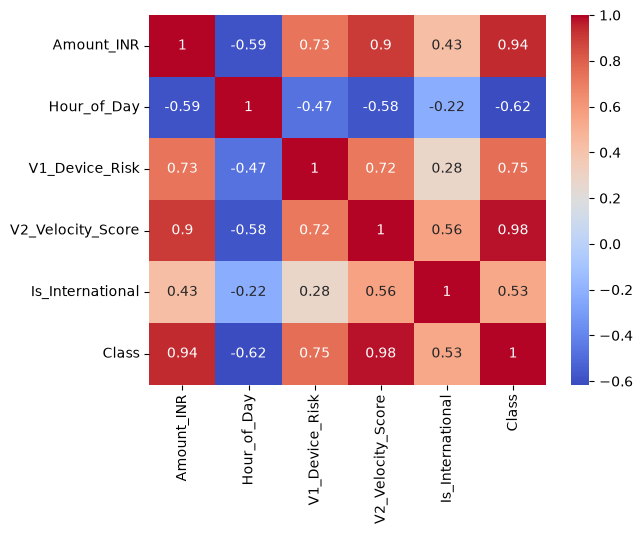

In [13]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

In [14]:
from sklearn.model_selection import train_test_split

# X = Features (The clues), y = Label (The answer)
X = df.drop(columns=['Class'])
y = df['Class']

# Split: 80% Training Data, 20% Testing Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((80, 5), (20, 5), (80,), (20,))

In [15]:
from sklearn.linear_model import LogisticRegression

# 1. Initialize and Train the Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("Model Training Complete!")

Model Training Complete!


In [16]:
model

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [17]:
model.get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': 0.0,
 'max_iter': 1000,
 'n_jobs': None,
 'penalty': 'deprecated',
 'random_state': None,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

In [18]:
predictions = model.predict(X_test) == y_test

In [19]:
model.score(X_test, y_test)

1.0

In [20]:
# 3. Create a clean table of the first 10 test cases WITHOUT actual answers
df = X_test.iloc[:10].copy().reset_index(drop=True)
df['Model_Prediction'] = predictions[:10]

print("\n--- FIRST 10 UNSEEN TEST TRANSACTIONS (ACTUAL LABEL HIDDEN) ---")
df


--- FIRST 10 UNSEEN TEST TRANSACTIONS (ACTUAL LABEL HIDDEN) ---


,Amount_INR,Hour_of_Day,V1_Device_Risk,V2_Velocity_Score,Is_International,Model_Prediction
0,10733.0,19,-0.29,-5.74,0,NaN
1,11786.0,21,-1.13,-7.07,1,True
2,10297.0,18,-0.06,-7.03,0,NaN
3,57479.0,1,3.79,1.66,0,NaN
4,1010.0,13,0.14,-7.41,0,NaN
5,13953.0,16,-0.25,-7.01,0,NaN
6,3535.0,15,-0.73,-4.49,0,NaN
7,86476.0,4,1.92,1.90,1,NaN
8,10898.0,15,-1.23,-6.43,0,NaN
9,10383.0,19,-0.44,-5.39,0,NaN
